---
title: "Figures: Portfolio Choice with CRRA Utility (Merton-Samuelson)"
execute:
  depends_on_env: [IC_EXEC_ENV]
---

Open this notebook in [Colab](https://colab.research.google.com/github/intertemporal-choice/intertemporal-choice.github.io/blob/main/content/asset_pricing/Portfolio-CRRA/Portfolio-CRRA.ipynb) or [Binder](https://mybinder.org/v2/gh/intertemporal-choice/intertemporal-choice.github.io/main?labpath=content/asset_pricing/Portfolio-CRRA/Portfolio-CRRA.ipynb) to run it without installing anything.

Draws the figures in [Portfolio Choice with CRRA Utility (Merton-Samuelson)](#sec:Portfolio-CRRA): the approximate risky share at each degree of relative risk aversion, and how far it is from the exactly optimal share, which is found here numerically. Run all the cells to redraw them into `figures/`; change the parameters to see how they respond.

The figures replace the ones Carroll drew in Mathematica for the handout ([source](https://www.econ2.jhu.edu/people/ccarroll/public/LectureNotes/AssetPricing/Portfolio-CRRA.zip)), whose solver left visible steps in the error curve.

In [ ]:
# Run anywhere: install the book's package (it brings econ-ark, numpy and matplotlib) if it
# is missing. Inside the book's own environment this does nothing.
try:
    import intertemporal_choice
except ImportError:
    %pip install -q git+https://github.com/intertemporal-choice/intertemporal-choice.github.io

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

from intertemporal_choice import style

style.use_book_style()

In [ ]:
r = 0.02      # log of the riskless return factor
phi = 0.03    # the premium: log of the expected risky return factor over the riskless one
sigma = 0.2   # standard deviation of the log risky return
rho = np.linspace(1.0, 5.0, 161)  # relative risk aversion

The chapter's approximation is $\varsigma = \varphi/(\rho\sigma^{2})$. The exactly optimal share maximizes the expected utility of next period's consumption per unit of assets, $\big(R(1-\varsigma)+\mathbf{R}_{t+1}\varsigma\big)^{1-\rho}/(1-\rho)$, where the log risky return is normal with mean $r+\varphi-\sigma^{2}/2$, so that the expected risky return factor is $e^{r+\varphi}$. Gauss-Hermite quadrature computes the expectation. Because utility is CRRA, the share depends on the risky return relative to the riskless one, not on $r$ itself.

In [ ]:
def share_approx(rho):
    return phi / (rho * sigma**2)


nodes, weights = np.polynomial.hermite_e.hermegauss(60)
weights = weights / weights.sum()
R_free = np.exp(r)
R_risky = np.exp(r + phi - sigma**2 / 2 + sigma * nodes)


def share_exact(rho):
    def minus_expected_utility(share):
        c = R_free * (1 - share) + R_risky * share
        if np.isclose(rho, 1.0):
            return -np.sum(weights * np.log(c))
        return -np.sum(weights * c ** (1 - rho)) / (1 - rho)

    return minimize_scalar(minus_expected_utility, bounds=(0, 1), method="bounded",
                           options={"xatol": 1e-12}).x


approx = share_approx(rho)
exact = np.array([share_exact(x) for x in rho])

for x in (1, 2, 3, 5):
    print(f"rho = {x}: approximate share {share_approx(x):.3f}, exact {share_exact(x):.3f}")

rho = 1: approximate share 0.750, exact 0.752
rho = 2: approximate share 0.375, exact 0.374
rho = 3: approximate share 0.250, exact 0.248
rho = 5: approximate share 0.150, exact 0.148


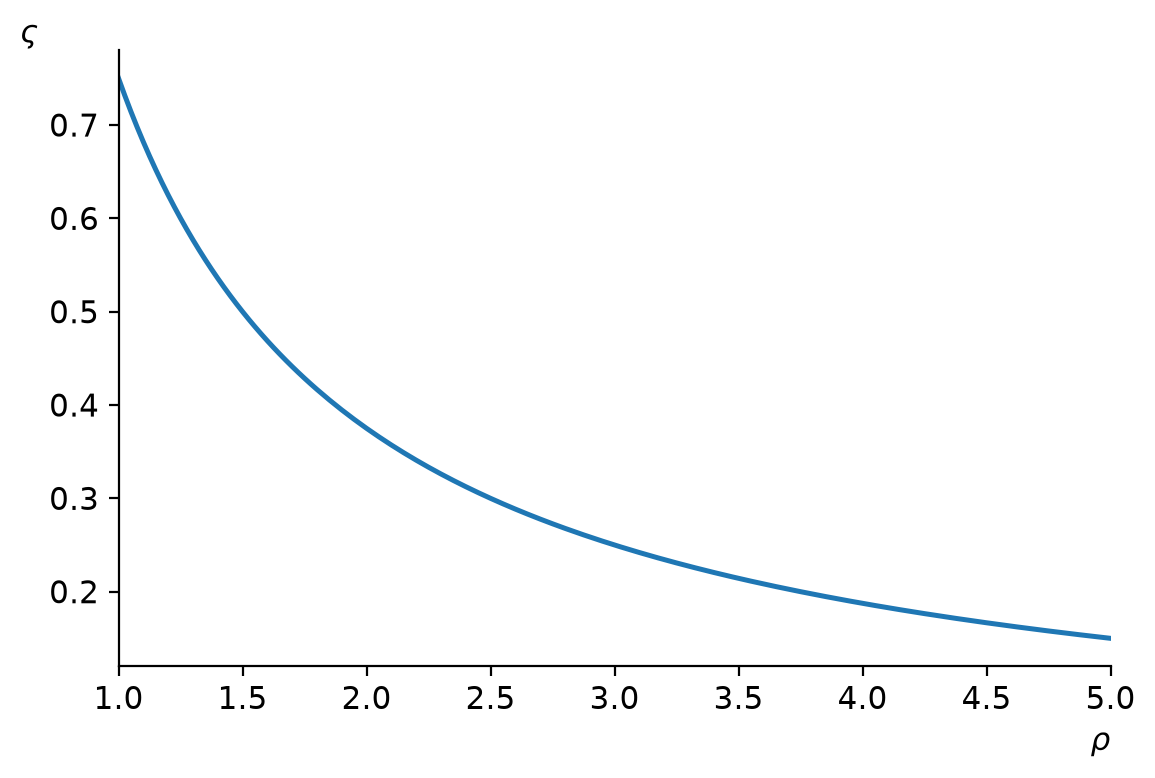

In [ ]:
fig, ax = plt.subplots()
ax.plot(rho, approx, color="C0")
ax.set_xlim(rho[0], rho[-1])
ax.set_xlabel(r"$\rho$", loc="right")
ax.set_ylabel(r"$\varsigma$", loc="top", rotation=0)
style.save(fig, "ShareVsCRRA")

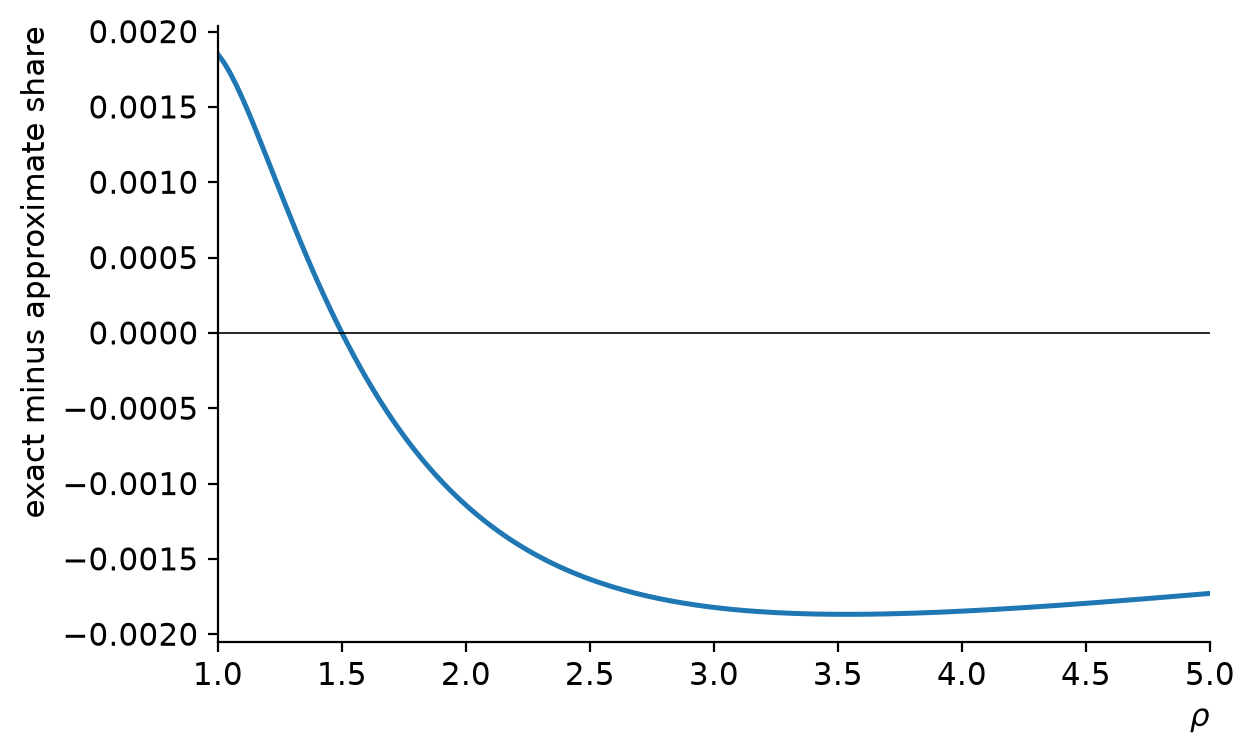

In [ ]:
fig, ax = plt.subplots()
ax.plot(rho, exact - approx, color="C0")
ax.axhline(0, color="black", linewidth=0.6)
ax.set_xlim(rho[0], rho[-1])
ax.set_xlabel(r"$\rho$", loc="right")
ax.set_ylabel("exact minus approximate share", loc="top")
style.save(fig, "ShareApproxErr")